In [1]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time
sys.path.append('../../code/sim_course_pycharm')
from utils import *

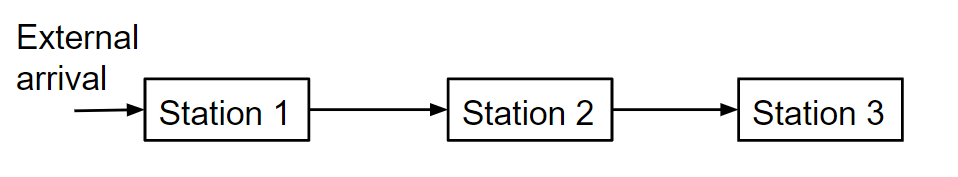

In [2]:
Image('../../Images/trans_3_stations.png', width=720)

<div dir="rtl">

# הקצאת משאבים: 
    
## נאמר יש לכם מערכת שירות עם 3 תחנות ויש לכם 6 שרתים, כיצד תחלקו את השרתים?
    
### חלוקה מאוזנת של 2 שרתים לכל תחנה נשמע הגיוני, נכון?
    
### ובכן, זה תלוי בזמני שירות בכל תחנה, אולי יש תחנה מסוימת שדורשת זמן שירות רב ואילו תחנות אחרות שדורשות זמני שירות קצרים. 
    
### לפיכך, צריך לבחון את יותר לעומק. 
    
### נרצה לדעת מה קצב הגעה הגעה לכל תחנה וגם קצב ישרות בכל תחנה.
    
### בשלב זה זמנים בין השעות וזמני שירות מפולגים מעריכית.
    
###  נתונים: זמני שירות ממוצע בדקות.
    
### תחנה ראשונה :10
    
### תחנה שנייה: 15 
    
### תחנה שלישית: 60

### Station 1: 1, Station 2: 2, Station 3: 3

In [3]:
num_stations = 3
capacities = {1: 1, 2:2, 3:3}
sim_time = 240
dict_sch = {0: 1/20}

arrival_scd_pd = convert_dict_to_pd(dict_sch)
num_stations = 3
mu = np.zeros(num_stations)
mu[0] = 1/10
mu[1] = 1/15
mu[2] = 1/60


probs1 = compute_trans_probs_tandem_queues(dict_sch, sim_time, capacities, num_stations, mu)

all_means_1 = []
for station in range(1, 1 + num_stations):
    all_means_1.append(((probs1[station]*np.arange(100)).sum(axis = 1)).mean())
    
all_means_1, np.array(all_means_1).mean()

100%|██████████████████████████████████████████████████████████████████████████████████| 5000/5000 [27:52<00:00,  2.99it/s]


([np.float64(0.8494082987551868),
  np.float64(0.7145203319502075),
  np.float64(2.0840871369294605)],
 np.float64(1.216005255878285))

In [4]:
all_means_1

[np.float64(0.8494082987551868),
 np.float64(0.7145203319502075),
 np.float64(2.0840871369294605)]

### Station 1: 2,  Station 2: 2, Station 3: 2

In [5]:
capacities = {1: 2, 2:2, 3:2}
dict_sch = {0: 1/20, 481:1/12.5}
sim_time = 240
arrival_scd_pd = convert_dict_to_pd(dict_sch)
arrival_scd_pd

,LB_time,arrival_rate
0,0.0,0.05
1,481.0,0.08


In [6]:
capacities = {1: 2, 2:2, 3:2}
dict_sch = {0: 1/20, 481:1/12.5}
sim_time = 240
arrival_scd_pd = convert_dict_to_pd(dict_sch)
num_stations = 3
mu = np.zeros(num_stations)
mu[0] = 1/10
mu[1] = 1/15
mu[2] = 1/60

probs2 = compute_trans_probs_tandem_queues(dict_sch, sim_time, capacities, num_stations, mu)

all_means_2 = []
for station in range(1, 1 + num_stations):
    all_means_2.append(((probs2[station]*np.arange(100)).sum(axis = 1)).mean())
    
all_means_2, np.array(all_means_2).mean()

100%|██████████████████████████████████████████████████████████████████████████████████| 5000/5000 [23:38<00:00,  3.52it/s]


([np.float64(0.5006672199170125),
  np.float64(0.7538340248962657),
  np.float64(2.635151867219917)],
 np.float64(1.2965510373443985))

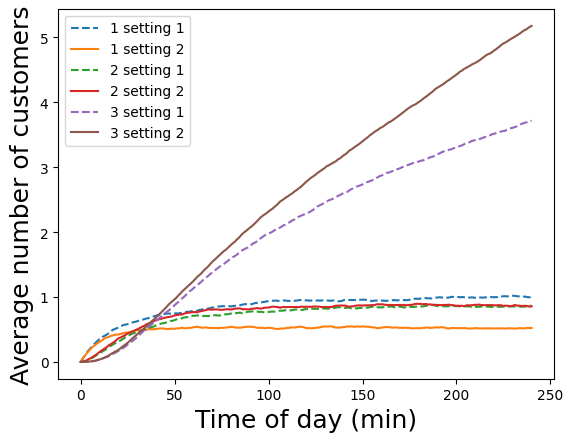

In [7]:
plt.figure()
for station in range(1, 1 + num_stations):
    
    plt.plot(np.arange(241),(probs1[station]*np.arange(100)).sum(axis = 1), ls = 'dashed',label = str(station) + ' setting 1')
    
    plt.plot(np.arange(241),(probs2[station]*np.arange(100)).sum(axis = 1), label =  str(station) + ' setting 2')
    
plt.xlabel('Time of day (min)', fontsize = 18)
plt.ylabel('Average number of customers', fontsize = 18)
plt.legend()
plt.show()

<div dir="rtl">

### נראה שחלוקה מאוזנת לא הייתה עדיפה על פני חלוקה של 3 שרתים בתחנה 3, 2 בתחנה 2 ושרת אחד בתחנה 1.
    
### על ידי מעבר של משאב מתחנה 1 ל-תחנה 3 - הפחתנו את כמות הצרכנים במערכת הממוצע לתחנה לאורך זמן מ1.27 ל1.2

<div dir="rtl">

## לפעמים לא נתעניין רק בממוצעים, למשל אולי נתעניין בהסתברות שיהיו יותר מ5 צרכנים בתור כי יש מספר מקומות מוגבל. 

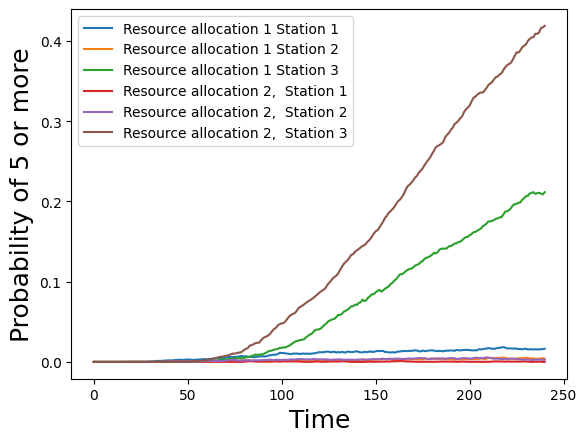

In [8]:
plt.figure()
for station in range(1, 1+ num_stations):
    plt.plot(np.arange(241), (probs1[station][:,6:].sum(axis= 1)), label = 'Resource allocation 1 Station '+str(station))
    
for station in range(1, 1+ num_stations):
    plt.plot(np.arange(241), (probs2[station][:,6:].sum(axis= 1)), label = 'Resource allocation 2,  Station '+str(station))
    
plt.xlabel('Time', fontsize = 18)
plt.ylabel('Probability of 5 or more', fontsize= 18)
plt.legend()
plt.show()

<div dir="rtl">

### תחנת חלוקת משאבים 1: ההסתברות מגיעה ל0.2 ואילו תחנת חלוקת משאבים 2 ההסתברות מגיעה ל0.4. נראה שאם מעוניינים בתור קצר הגברת המשאבים בתחנה 3 נחוץ ביותר.

<div dir="rtl">

# תפוקה: 
    
## למעלה ניסינו למזער זמני המתנה של צרכנים. דרך אחרת להסתכל על זה - מקסום צרכנים שמשורתים. במערכות פשוטות האופטימזציה שממזערת זמני המתנה היא זו שתמקסם תפוקה. 
    
## במערכות יציבות חישוב התפוקה נעשה באופן הבא. 

## יהי $X$ המתאר את קצב הפריטים המשורתים ליחידת זמן. החישוב לתור יחיד עם שרת בודד הוא:
    
### $$ X = \mu \rho $$
    
### אבל אנחנו יודעים ש$\rho$ זה הנצילות ו:
    
### $$ \rho = \frac{\lambda}{\mu} $$
    
### לפיכך:
    
### $$ X = \mu \rho  = \mu  \frac{\lambda}{\mu} = \lambda $$
    
### בכלל לא תלוי בקצב השירות. אבל זו תוצאה שקוראת רק במצב יציב.
    
### כשהמערכת לא יציבה ואפילו משתנה חישובים אנלטיים מאד מסובכים. אז מה נעשה?
    
    
    

### You guessed it... Simulation!!!!!!!!!!!

<div dir="rtl">

### נניח יש לנו מערכת דומה לזו שלמעלה. כלומר 3 תחנות בתור. הפעם אין לנו קצב הגעה, אלא תור אינסופי בתחנה הראשונה. המטרה היא לעשות הקצאת משאבים כך שכמות המוצרים שנייצר - כלומר עברו  בכל שלוש התחנות יהיה מקסימלי. 
    
### נניח שיש לנו 8 משאבים ונרצה לחלק אותם לפי 3 תחנות. נניח ניתן לתחנה 1 שני משאבים ואילו ל-2 ו-3 ניתן 3.
    
### נתונים נוספים: קבצי שירות לפי תחנות:
    
#### 1: 1/10
#### 2: 1/45
#### 3: 1/55
    
### נריץ את הסימולציה למשל יום עבודה של 8 שעות ביחידות זמן של דקות - כלומר 480 דקות. 

In [9]:
sim_time = 480
num_stations = 3
capacities = {1: 2, 2:3, 3:3}
mu = np.zeros(num_stations)

mu[0] = 1/10
mu[1] = 1/45
mu[2] = 1/55

num_jobs = 500
num_simulations = 5000

counts = compute_counts(num_stations, sim_time, capacities, mu, num_jobs, num_simulations)

100%|████████████████████████████████████████████████████████████████████████████████| 5000/5000 [1:25:35<00:00,  1.03s/it]


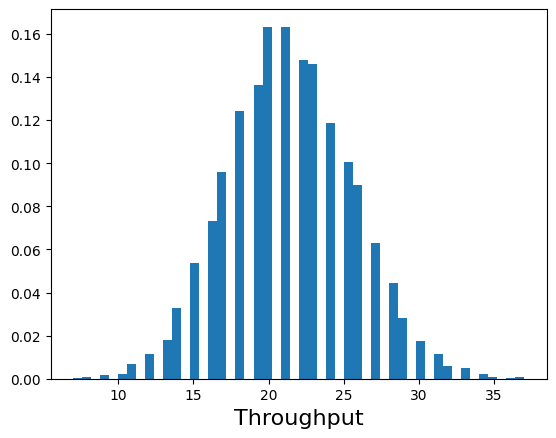

In [10]:
plt.figure()
plt.hist(counts, bins = 50, density = True)
plt.xlabel('Throughput', fontsize = 16)
plt.show()

In [11]:
counts = np.array(counts)  
counts[counts>30].shape[0]/counts.shape[0]

0.016

<div dir="rtl">

### מה ההסתברות שהתפוקה תהיה גדולה מ-30?
    

<div dir="rtl">

### מה התוחלת של התפוקה?

In [12]:
counts.mean()

np.float64(21.3206)

In [13]:
sim_time = 480
num_stations = 3
capacities = {1: 3, 2:3, 3:2}
mu = np.zeros(num_stations)

mu[0] = 1/10
mu[1] = 1/45
mu[2] = 1/55

num_jobs = 500
num_simulations = 1000

counts2 = compute_counts(num_stations, sim_time, capacities, mu, num_jobs, num_simulations)

100%|██████████████████████████████████████████████████████████████████████████████████| 1000/1000 [13:07<00:00,  1.27it/s]


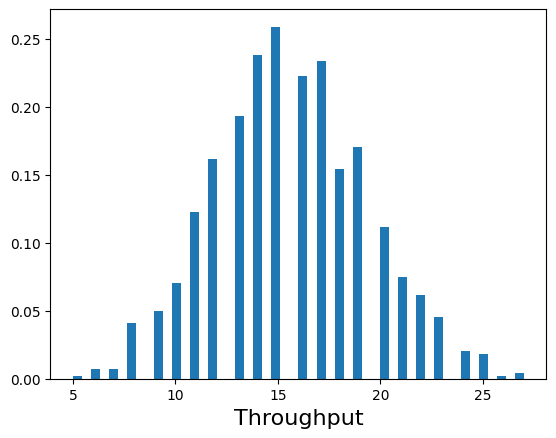

In [14]:
plt.figure()
plt.hist(counts2, bins = 50, density = True)
plt.xlabel('Throughput', fontsize = 16)
plt.show()

In [15]:
counts2 = np.array(counts2)  
counts2[counts2>30].shape[0]/counts2.shape[0]

0.0

In [16]:
counts2.mean()

np.float64(15.618)

<div dir="rtl"> 

### נראה שהשינוי בהקצאת משאבים הורידה את התפוקה מ21 ל-15.

<div dir="rtl">

    
## למה אנחנו מנתחים מערכת תורים שכזאת?
    
### אנחנו נרצה לעשות שני דברים עיקריים - לעשות אופטימיזציה של המשאבים שלנו  או לראות האם אנחנו עומדים בתנאי סף כלשהם.
    
### למשל: כמו בשאלה מקודם נרצה לדעת באילו תחנות עלינו להקצות שרתים כך שתהיה תפוקה מקסימלית.
    
### למשל: בcall centers זמן המתנה מקסימלי שמותר הוא עד 6 דקות - אחרת החברה נקנסת
    


<div dir="rtl">

### בעית אופטימיזציה:
    
### אתם מנהלים את הפס ייצור של שלוש תחנות בטור. כדי לסיים מוצר צריך לעבור דרך שלוש התחנות. המטרה היא לייצר כמה שיותר מוצרים. ביום יש שמונה שעות עבודה. ברגע שנגמר הזמן כל המוצרים שנמצאים בעיבוד באחת המכונות נזרקים לפח. המפעל בשלב תכנון והוא יכול לבחור כמות מכונות בכל תחנה ואיכות המכונות.
    
### מספר מכונות: בכל תחנה ניתן לבחור אם רוצים מכונה אחת או שתיים. 
    
### איכות מכונה: מכונה יכולה בהסתברות מסוימת לפסול את המוצר. אם מוצר נפסל אז הוא נזרק לפח. יש 2 סוגים של מכונות A ו-B. מכונה סוג A יותר יקרה לתחזוק אך עם הסתברות יותר נמוכה לפסילה.
    
### ורווח עלויות:
    
#### * עלות מכונה A ליום 10 ואילו עלות מכונה B ליום 8. 
#### * רווח מיחידה בודדת הוא 12 

### * נתונים נוספים: 
#### הסתברות לפסילה מכונה A בכל תחנה שהיא : 0.05
#### הסתברות לפסילה מכונה B בכל תחנה שהיא : 0.07
    
### פונקציית מטרה: 

## $L_{i,j}$ number of type $i$ machines in station $j$, $i \in \{a, b\}$, and $j \in \{1,2,3 \}$.
## N is the number of non damged products in a single day

## $$ cost(L) = 12*R E[N] - 10 \sum_{j=1}^3 L_{a,j}- 8 \sum_{j=1}^3 L_{b,j} $$

### 2 servers in each station. In station 1-2 type A and type B in station 3

In [17]:
sim_time = 480
num_stations = 3
capacities = {1: 2, 2:2, 3:2}
mu = np.zeros(num_stations)

mu[0] = 1/22
mu[1] = 1/25
mu[2] = 1/20

num_jobs = 1500
num_simulations = 1000

machine_types = np.array([0.05,0.05,0.07])

counts3 = compute_counts_machine_types(num_stations, sim_time, capacities, mu, num_jobs, num_simulations, machine_types)

NameError: name 'compute_counts_machine_types' is not defined

In [ ]:
cost = 12*np.array(counts3).mean() - 10*4-8*2
cost

### 2 servers in each station. In station 1-2-3 type A

In [ ]:
sim_time = 480
num_stations = 3
capacities = {1: 2, 2:2, 3:2}
mu = np.zeros(num_stations)

mu[0] = 1/22
mu[1] = 1/25
mu[2] = 1/20

num_jobs = 1500
num_simulations = 1000

machine_types = np.array([0.05,0.05,0.05])

counts3a = compute_counts_machine_types(num_stations, sim_time, capacities, mu, num_jobs, num_simulations, machine_types)

In [ ]:
costa = 12*np.array(counts3a).mean() - 10*6
costa

### 2 servers in each station. In station 1-2-3 type B

In [ ]:
sim_time = 480
num_stations = 3
capacities = {1: 2, 2:2, 3:2}
mu = np.zeros(num_stations)

mu[0] = 1/22
mu[1] = 1/25
mu[2] = 1/20

num_jobs = 1500
num_simulations = 1000

machine_types = np.array([0.07,0.07,0.07])

counts3b = compute_counts_machine_types(num_stations, sim_time, capacities, mu, num_jobs, num_simulations, machine_types)

In [ ]:
costb = 12*np.array(counts3b).mean() - 8*6
costb

### 2 servers in each station. In station 1 type A and type B in station 2-3

In [ ]:
sim_time = 480
num_stations = 3
capacities = {1: 2, 2:2, 3:2}
mu = np.zeros(num_stations)

mu[0] = 1/22
mu[1] = 1/25
mu[2] = 1/20

num_jobs = 1500
num_simulations = 1000

machine_types = np.array([0.05,0.07,0.07])

counts3c = compute_counts_machine_types(num_stations, sim_time, capacities, mu, num_jobs, num_simulations, machine_types)

In [ ]:
costc = 12*np.array(counts3c).mean()-10*2 - 8*4
costc, np.array(counts3c).mean()

### 2 servers in station 1 and 2, one server in station 3. All are type A

In [ ]:
sim_time = 480
num_stations = 3
capacities = {1: 2, 2:2, 3:1}
mu = np.zeros(num_stations)

mu[0] = 1/22
mu[1] = 1/25
mu[2] = 1/20

num_jobs = 1500
num_simulations = 1000

machine_types = np.array([0.05,0.05,0.05])

counts3d = compute_counts_machine_types(num_stations, sim_time, capacities, mu, num_jobs, num_simulations, machine_types)

In [ ]:
costd = 12*np.array(counts3d).mean()-10*5 
costd, np.array(counts3d).mean()

### 2 servers in station 1 and 2, one server in station 3. All are type B

In [ ]:
sim_time = 480
num_stations = 3
capacities = {1: 2, 2:2, 3:1}
mu = np.zeros(num_stations)

mu[0] = 1/22
mu[1] = 1/25
mu[2] = 1/20

num_jobs = 1500
num_simulations = 1000

machine_types = np.array([0.07,0.07,0.07])

counts3d_ = compute_counts_machine_types(num_stations, sim_time, capacities, mu, num_jobs, num_simulations, machine_types)

In [ ]:
costd_ = 12*np.array(counts3d_).mean()-8*5 
costd_

### 2 servers in station 1 and 2, one 3 servers in station 3. All are type A

In [ ]:
sim_time = 480
num_stations = 3
capacities = {1: 2, 2:2, 3:3}
mu = np.zeros(num_stations)

mu[0] = 1/22
mu[1] = 1/25
mu[2] = 1/20

num_jobs = 1500
num_simulations = 1000

machine_types = np.array([0.05,0.05,0.05])

counts3e = compute_counts_machine_types(num_stations, sim_time, capacities, mu, num_jobs, num_simulations, machine_types)

In [ ]:
coste = 12*np.array(counts3e).mean()-10*7 
coste

### 2 servers in station 1 and 2, one 3 servers in station 3. All are type B

In [ ]:
sim_time = 480
num_stations = 3
capacities = {1: 2, 2:2, 3:3}
mu = np.zeros(num_stations)

mu[0] = 1/22
mu[1] = 1/25
mu[2] = 1/20

num_jobs = 1500
num_simulations = 1000

machine_types = np.array([0.07,0.07,0.07])

counts3f = compute_counts_machine_types(num_stations, sim_time, capacities, mu, num_jobs, num_simulations, machine_types)

In [ ]:
costf = 12*np.array(counts3f).mean()-8*7 
costf

### 1 server in stations 1 and 3, two servers in station 2. All are type B

In [ ]:
sim_time = 480
num_stations = 3
capacities = {1: 1, 2:2, 3:1}
mu = np.zeros(num_stations)

mu[0] = 1/22
mu[1] = 1/25
mu[2] = 1/20

num_jobs = 1500
num_simulations = 1000

machine_types = np.array([0.07,0.07,0.07])

counts3g_ = compute_counts_machine_types(num_stations, sim_time, capacities, mu, num_jobs, num_simulations, machine_types)

In [ ]:
costg = 12*np.array(counts3g_).mean()-8*4 
costg